# CodeAlpha Task 4 — Sales Prediction

This notebook reproduces the complete experiment through `analysis.py` and displays its report artifacts. The goal is conditional prediction of Sales from TV, Radio, and Newspaper; no dates, customer segments, or online-platform variables are supplied. All numbers use observed dataset units. Marketing associations and hypothetical scenarios are not causal effects or assured ROI.


## Objective, data, and evaluation design

The supplied CSV has 200 observations. Its verified sequential index is excluded from predictors. Seed 42 reserves a 20% untouched test set; five-fold CV on the training partition compares six predeclared models. Imputation, scaling, and feature construction remain inside fold-specific pipelines. Model selection uses CV RMSE before test scoring. The task document references [Advertising.csv on Kaggle](https://www.kaggle.com/datasets/bumba5341/advertisingcsv); actual input is the uploaded CSV and upstream licensing/units are unverified.


In [1]:
from pathlib import Path
import importlib.util
import json
import pandas as pd
from IPython.display import display, Markdown, Image

# Jupyter should start in this project directory or its notebooks subdirectory.
ROOT = Path.cwd().resolve()
if not (ROOT / "analysis.py").is_file() and (ROOT.parent / "analysis.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "analysis.py").is_file():
    raise RuntimeError("Start this notebook with its working directory set to the project root.")
spec = importlib.util.spec_from_file_location("sales_analysis", ROOT / "analysis.py")
analysis = importlib.util.module_from_spec(spec)
spec.loader.exec_module(analysis)
metrics = analysis.main(["--data", str(ROOT / "data" / "Advertising.csv"), "--output-dir", str(ROOT / "outputs")])


{
  "selected_model": "Quadratic ridge (alpha=1)",
  "heldout": {
    "selected_model": {
      "mae": 0.48478260151647445,
      "rmse": 0.6210142782816875,
      "r2": 0.9877815328354451
    },
    "dummy_mean_baseline": {
      "mae": 4.9625,
      "rmse": 5.631496248777939,
      "r2": -0.004757260886999015
    }
  }
}


## Audit and model comparison

The row identifier never enters a predictor. CV fold standard deviations describe fold variation, not confidence intervals. Candidate selection can inflate the winning CV result; the held-out result is the independent check.


,column,missing_count
0,TV,0
1,Radio,0
2,Newspaper,0
3,Sales,0


Rows: 200
Excluded index: ['Unnamed: 0']
Duplicates ignoring index: 0


,model,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_rmse_std,cv_r2_mean,cv_r2_std
0,Quadratic ridge (alpha=1),0.441089,0.111265,0.671396,0.375368,0.977113,0.024513
1,TV x Radio interaction,0.700944,0.103968,0.968136,0.369574,0.956985,0.031591
2,Random forest,0.738383,0.093171,1.020755,0.246678,0.956248,0.017095
3,Linear regression,1.237076,0.182463,1.675810,0.297411,0.870265,0.080324
4,Ridge (alpha=1),1.237077,0.175801,1.677041,0.288803,0.870527,0.078640
5,Dummy mean,4.191006,0.233442,5.150294,0.445445,-0.099118,0.090939


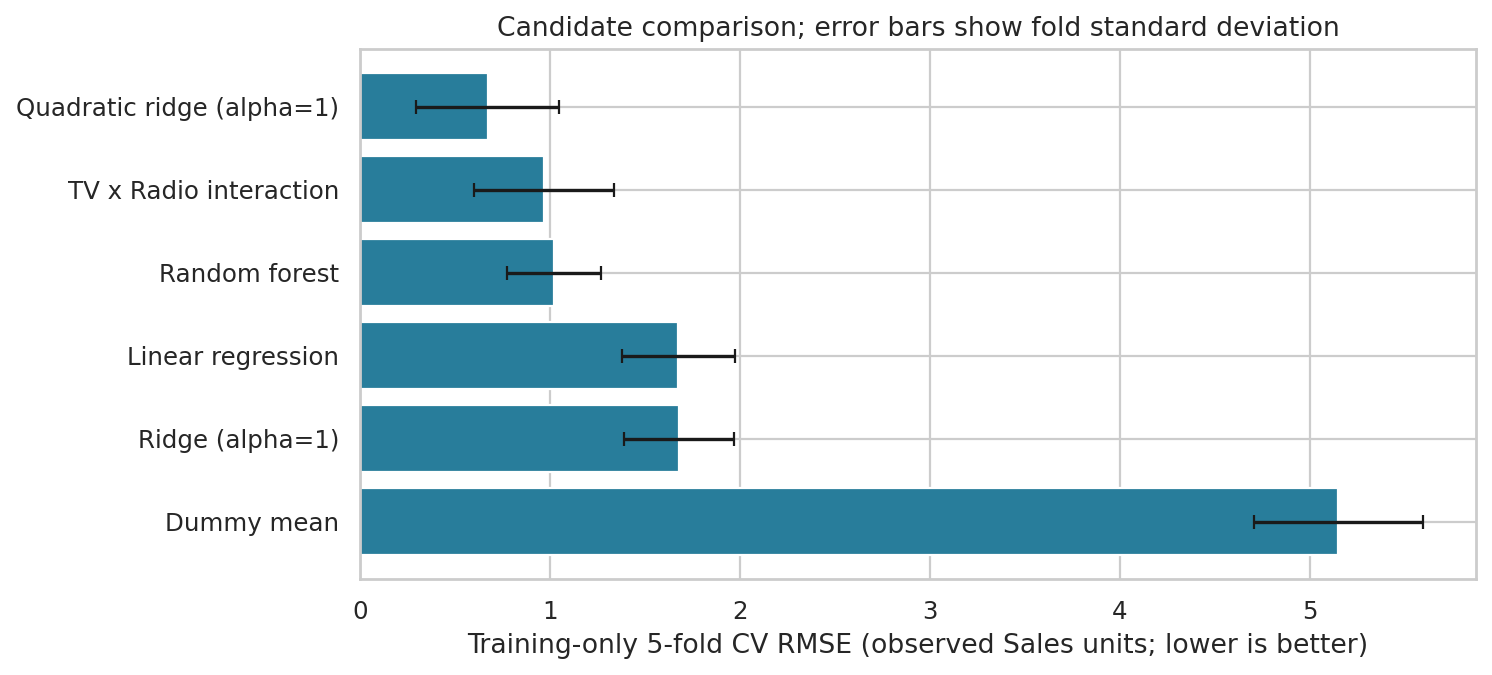

In [2]:
display(pd.DataFrame(metrics["data_audit"]["missing_values"].items(), columns=["column", "missing_count"]))
print("Rows:", metrics["data_audit"]["modeling_rows"])
print("Excluded index:", metrics["data_audit"]["dropped_verified_index_columns"])
print("Duplicates ignoring index:", metrics["data_audit"]["duplicate_observations_ignoring_index"])
display(pd.read_csv(ROOT / "outputs" / "tables" / "cross_validation_summary.csv"))
display(Image(filename=str(ROOT / "outputs" / "charts" / "02_training_cv_comparison.png")))


## Held-out results

MAE and RMSE use observed Sales units; lower is better. R² compares squared error to a test-mean reference; higher is better. The mean baseline itself is fitted using only training observations.


,mae,rmse,r2
selected_model,0.484783,0.621014,0.987782
dummy_mean_baseline,4.962500,5.631496,-0.004757


,source_row_id,TV,Radio,Newspaper,actual_sales,predicted_sales,dummy_mean_prediction,residual_actual_minus_predicted
0,10,199.8,2.6,21.2,10.6,11.577817,14.1,-0.977817
1,16,195.4,47.7,52.9,22.4,22.563091,14.1,-0.163091
2,17,67.8,36.6,114.0,12.5,12.496982,14.1,0.003018
3,19,69.2,20.5,18.3,11.3,10.266886,14.1,1.033114
4,31,292.9,28.3,43.2,21.4,20.789444,14.1,0.610556
5,46,175.1,22.5,31.5,14.9,15.569699,14.1,-0.669699
6,56,198.9,49.4,60.0,23.7,23.228759,14.1,0.471241
7,57,7.3,28.1,41.4,5.5,7.065488,14.1,-1.565488
8,61,53.5,2.0,21.4,8.1,7.813307,14.1,0.286693
9,66,69.0,9.3,0.9,9.3,8.977077,14.1,0.322923


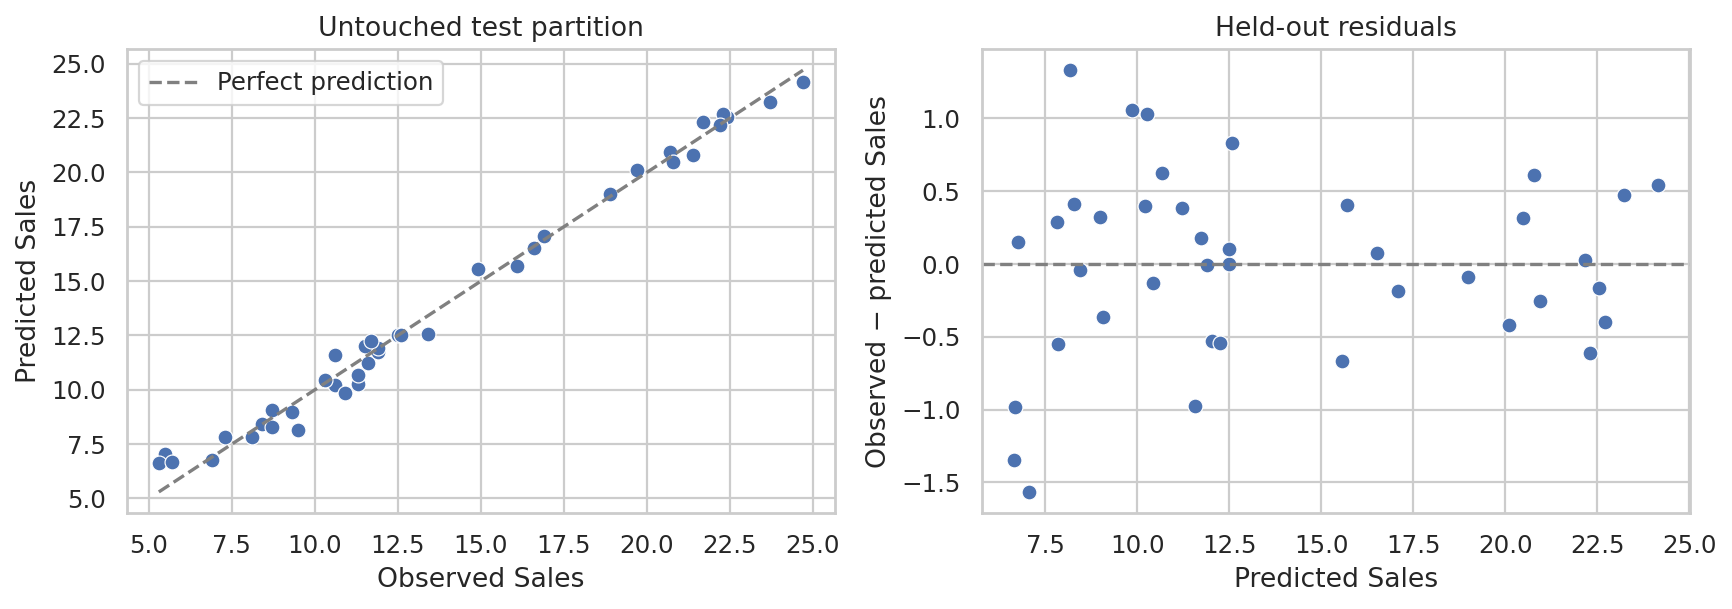

In [3]:
display(pd.DataFrame(metrics["heldout"]).T)
display(pd.read_csv(ROOT / "outputs" / "heldout_predictions.csv").head(10))
display(Image(filename=str(ROOT / "outputs" / "charts" / "03_heldout_predictions_and_residuals.png")))


## Interpretation and scenarios

The linear reference coefficients describe conditional associations within a model fitted only on the training data. Scenarios alter one channel from an observed training reference and stay within marginal training ranges; synthetic joint combinations need not have observational support. They are not causal uplift estimates, ROI guarantees, or budget recommendations.


,feature,training_standard_deviation,coefficient_per_training_standard_deviation,coefficient_per_observed_input_unit
0,TV,84.154634,3.764196,0.044730
1,Radio,14.758878,2.792307,0.189195
2,Newspaper,20.272798,0.055976,0.002761


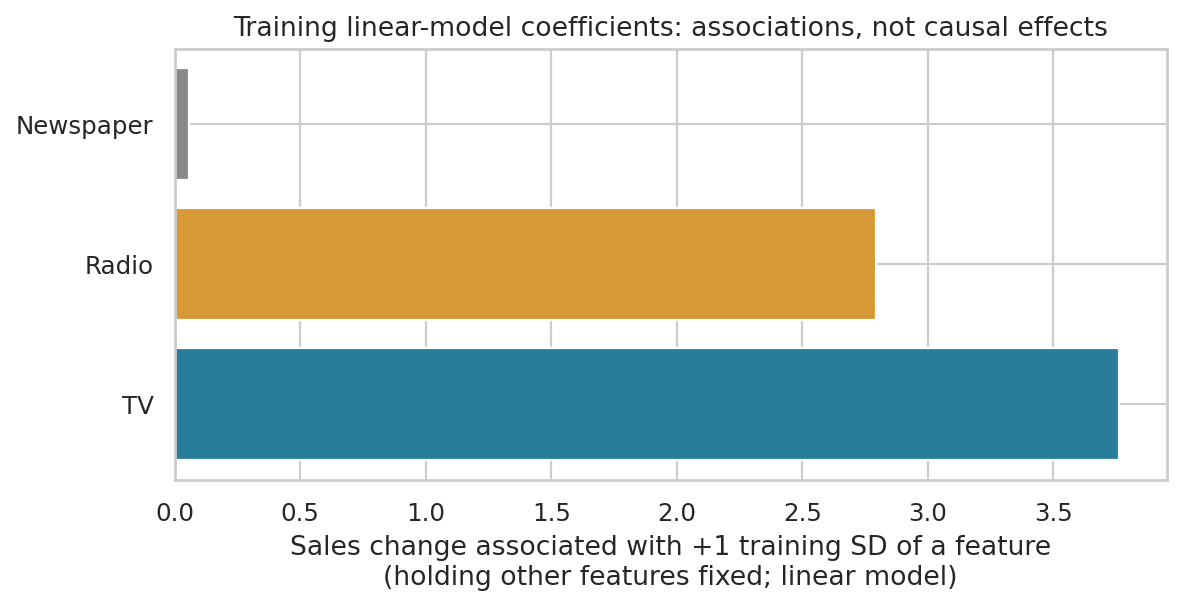

,scenario,TV,Radio,Newspaper,predicted_sales,difference_from_reference_prediction
0,Observed training reference,147.30,23.90,19.10,14.662382,0.000000
1,TV −20% (range clipped),117.84,23.90,19.10,13.268264,-1.394118
2,TV +20% (range clipped),176.76,23.90,19.10,15.902980,1.240598
3,Radio −20% (range clipped),147.30,19.12,19.10,13.759351,-0.903031
4,Radio +20% (range clipped),147.30,28.68,19.10,15.570216,0.907834
5,Newspaper −20% (range clipped),147.30,23.90,15.28,14.643152,-0.019230
6,Newspaper +20% (range clipped),147.30,23.90,22.92,14.680615,0.018233


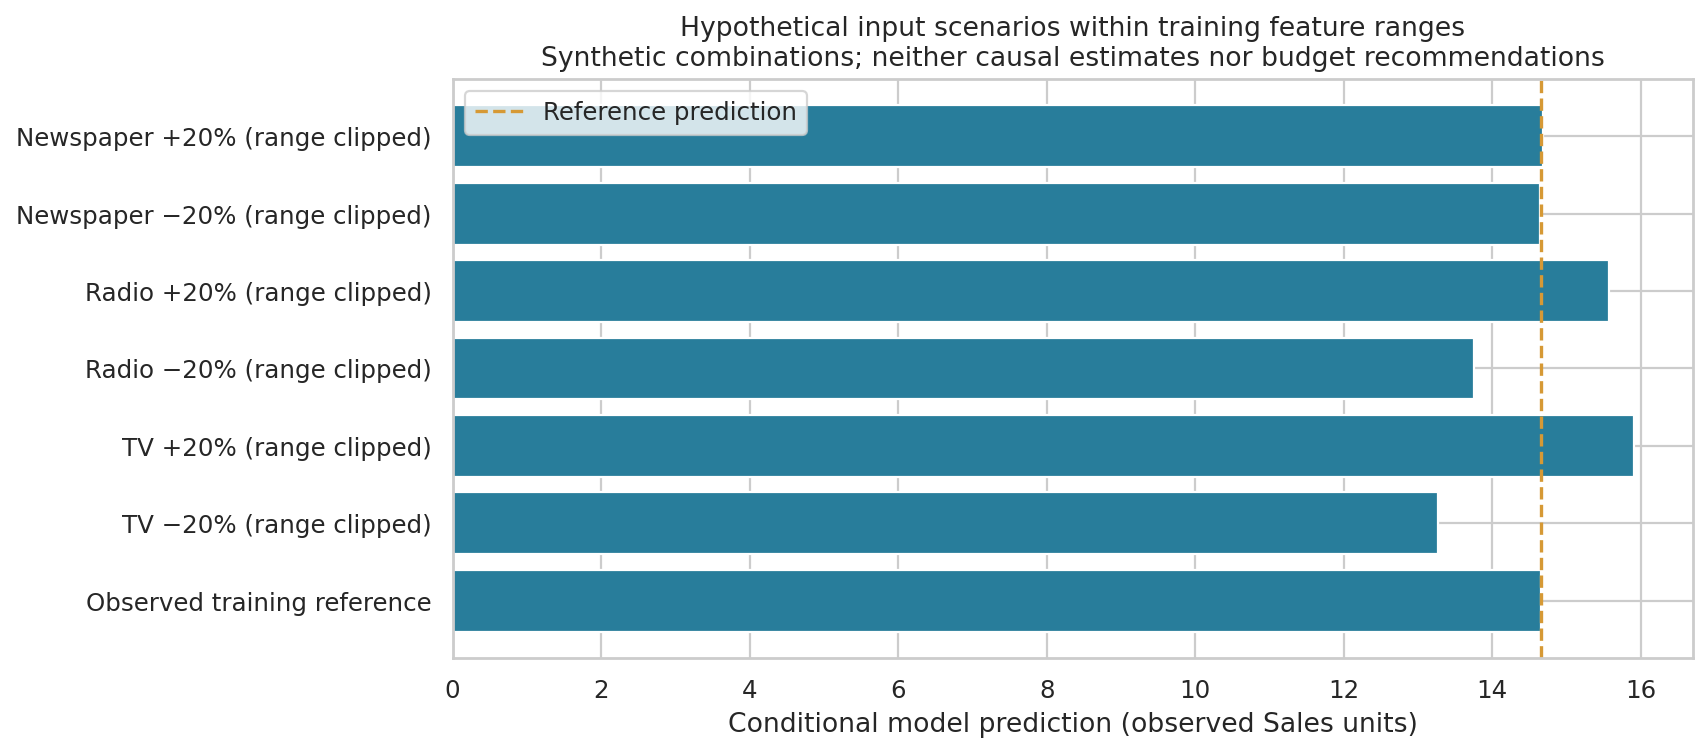

In [4]:
display(pd.read_csv(ROOT / "outputs" / "tables" / "training_linear_associations.csv"))
display(Image(filename=str(ROOT / "outputs" / "charts" / "04_linear_association_coefficients.png")))
display(pd.read_csv(ROOT / "outputs" / "tables" / "hypothetical_scenarios.csv"))
display(Image(filename=str(ROOT / "outputs" / "charts" / "05_hypothetical_scenarios.png")))


## Full design report, limitations, and reproducibility

The generated report includes results, data limitations, and next steps. A date-stamped dataset and chronological validation are required for a future forecast; causal marketing decisions require an identified intervention design.


In [5]:
display(Markdown((ROOT / "outputs" / "summary.md").read_text(encoding="utf-8")))


# Sales Prediction — Design Report

## Objective
Predict Sales from TV, Radio, and Newspaper advertising measurements using the supplied Advertising.csv. This is conditional out-of-sample regression; the data do not support a dated future sales forecast, customer segmentation, or online-platform analysis.

## Data and audit
The supplied file has 200 rows and five columns. The verified sequential `Unnamed: 0` column is excluded from predictors and retained only as a source-row identifier. There are 0 missing measurements and 0 duplicate observations ignoring the identifier. Features and Sales are numeric. Values use **observed dataset units**: the file provides no verified currency or sales-volume unit. The task document points to [Advertising.csv on Kaggle](https://www.kaggle.com/datasets/bumba5341/advertisingcsv), while the actual input is the user's uploaded CSV. Upstream provenance and licensing were not independently verified.

Audit and source checksum: [metrics.json](metrics.json). Descriptive statistics and correlations: [tables](tables/). Correlations and scatterplots describe associations, not causal marketing effects.

## Method and reproducibility
Seed 42; a fixed random 80/20 split creates 160 training rows and 40 held-out test rows. All six predeclared candidate pipelines use exactly the same shuffled five-fold training CV splits. Median imputation, scaling, polynomial/interaction transformations, and model fitting occur inside each fold. Candidates use fixed hyperparameters documented in `make_models()`. The lowest mean CV RMSE selects **Quadratic ridge (alpha=1)** before either final held-out evaluation is computed. The held-out set is used once for the selected model and the mean-prediction baseline. Source identifiers never enter the model. No refit on all observations is performed, so reported artifacts retain the split used for evaluation.

| Candidate | CV MAE | CV RMSE ± fold SD | CV R² |
| --- | ---: | ---: | ---: |
| Quadratic ridge (alpha=1) | 0.441 | 0.671 ± 0.375 | 0.977 |
| TV x Radio interaction | 0.701 | 0.968 ± 0.370 | 0.957 |
| Random forest | 0.738 | 1.021 ± 0.247 | 0.956 |
| Linear regression | 1.237 | 1.676 ± 0.297 | 0.870 |
| Ridge (alpha=1) | 1.237 | 1.677 ± 0.289 | 0.871 |
| Dummy mean | 4.191 | 5.150 ± 0.445 | -0.099 |

Fold SD describes variation across these five folds, not a confidence interval. Selection across candidates can make the winning CV score optimistic; the test results are the independent check. See [fold-level results](tables/cross_validation_folds.csv).

## Held-out results
| Model | MAE | RMSE | R² |
| --- | ---: | ---: | ---: |
| Quadratic ridge (alpha=1) | 0.485 | 0.621 | 0.988 |
| Mean baseline | 4.963 | 5.631 | -0.005 |

MAE and RMSE use observed Sales units; lower is better. R² compares squared error with a test-mean reference; higher is better. Predictions for every held-out observation are in [heldout_predictions.csv](heldout_predictions.csv). Residual = observed minus predicted.

![Held-out predictions and residuals](charts/03_heldout_predictions_and_residuals.png)

## Marketing interpretation and hypothetical scenarios
The training-only linear reference model supplies standardized coefficients in [training_linear_associations.csv](tables/training_linear_associations.csv). A coefficient is the fitted Sales association with a one-training-standard-deviation feature increase while holding the other measured variables fixed. It describes the linear reference model, which may differ from the selected nonlinear predictor, and does not establish an intervention effect.

The fitted standardized associations are 3.764 for TV, 2.792 for Radio, and 0.056 for Newspaper, in observed Sales units per training standard deviation of the corresponding measurement. TV and Radio therefore show stronger conditional linear associations than Newspaper in this training sample; a small Newspaper coefficient does not establish that its true causal effect is zero.

![Linear association coefficients](charts/04_linear_association_coefficients.png)

Scenarios start from actual training source row 20 and vary one measured channel by −20% or +20%, clipped to that channel's training range. [Scenario inputs and predictions](tables/hypothetical_scenarios.csv) are hypothetical, with no observed outcome. Each input stays within its marginal training range; joint support is not assured. The results do not estimate causal uplift, guaranteed return on investment, or an optimal budget.

At this reference, predicted Sales is 14.662. The separate +20% input scenarios predict 15.903 for TV, 15.570 for Radio, and 14.681 for Newspaper while holding the other two values fixed. These are sensitivity examples from the selected model, not estimates of what an actual spend intervention will produce.

Business next step: prioritize measured, randomized TV and Radio channel experiments, including an appropriate Newspaper comparison, to test these observational hypotheses. Collect dates, verified spend and sales units, channel costs/revenue, and relevant segment labels before changing budgets. Predefine the experiment's outcome and validation period; this dataset alone does not justify reallocating spend.

![Hypothetical scenarios](charts/05_hypothetical_scenarios.png)

## Limitations and next steps
The small dataset contains no dates, customer segments, platform details, geography, prices, or economic controls. Random held-out accuracy does not establish future-period validity or transport to other markets. Unmeasured confounding, nonlinear structure, and correlated features limit interpretation. A time-stamped dataset and rolling chronological validation are needed for a future forecast; randomized or otherwise defensibly identified interventions are needed for causal marketing decisions. Verify provenance, permission to redistribute, and the measurement units before production use. The original user-supplied CSV is included for assignment reproducibility without an invented upstream license.

## Reproduction
From the project directory, install the pinned dependencies and run `python analysis.py`. The script uses paths relative to its own file and the noninteractive Agg renderer. `python /absolute/path/to/analysis.py` therefore works from another directory too. `--data` and `--output-dir` accept optional alternate paths. The notebook calls the same pipeline and displays its saved tables and charts. Seeds and numeric settings are fixed; package versions can affect final floating-point digits.
